# 6. Um batch: backward e otimizadores

Um único mini-batch: forward, backward, verificação dos gradientes e comparação entre SGD e Adam.

In [1]:
import sys
sys.path.append("..")  # so we can import the code in src/

import numpy as np
import matplotlib.pyplot as plt

from src.nn import MLP
from src.losses import bce
from src.optim import SGD, Adam
from src.gradcheck import check_gradient, numerical_gradient

## 1. O batch

8 amostras aleatórias, 4 atributos, alvos one-hot de 3 classes.

In [2]:
rng = np.random.default_rng(0)
X_batch = rng.normal(size=(8, 4))
y_batch = np.eye(3)[rng.integers(0, 3, 8)]


def new_model():
    # Same seed -> same initial weights, so every experiment starts from the same point.
    return MLP(input_size=4, hidden_sizes=[5], output_size=3,
               hidden_activation="tanh", output_activation="sigmoid", init="xavier", seed=0)


model = new_model()
print("X_batch:", X_batch.shape, " y_batch:", y_batch.shape)
for i, layer in enumerate(model.layers):
    print("layer %d: W %s, b %s, activation %s" % (i, layer.W.shape, layer.b.shape, layer.activation))

X_batch: (8, 4)  y_batch: (8, 3)
layer 0: W (4, 5), b (1, 5), activation tanh
layer 1: W (5, 3), b (1, 3), activation sigmoid


### Os pesos

Cada parâmetro é um `Tensor`: valores em `.data`, gradiente em `.grad`.

In [3]:
np.set_printoptions(precision=4, suppress=True)

for i, layer in enumerate(model.layers):
    print("layer %d  W %s" % (i, layer.W.shape))
    print(layer.W.data)
    print("layer %d  b %s" % (i, layer.b.shape))
    print(layer.b.data)
    print()

layer 0  W (4, 5)
[[ 0.2237 -0.3759 -0.7496 -0.7895  0.5116]
 [ 0.674   0.1741  0.3748  0.0712  0.7105]
 [ 0.5158 -0.812   0.5836 -0.7617  0.375 ]
 [-0.5297  0.5931  0.0677 -0.3271 -0.1263]]
layer 0  b (1, 5)
[[0. 0. 0. 0. 0.]]

layer 1  W (5, 3)
[[-0.817  -0.6508  0.2955]
 [ 0.2549  0.1999 -0.2015]
 [ 0.8612  0.8328  0.3214]
 [ 0.2606  0.3264 -0.1924]
 [-0.632   0.3836  0.0439]]
layer 1  b (1, 3)
[[0. 0. 0.]]



## 2. Backward

Os gradientes acumulam (`grad += ...`), por isso são zerados antes de cada `backward()`.

In [4]:
for p in model.parameters():
    p.zero_grad()

prediction = model.forward(X_batch)
loss = bce(prediction, y_batch)
loss.backward()

print("loss = %.6f" % float(loss.data))
for i, layer in enumerate(model.layers):
    print("layer %d: |dL/dW| = %.6f   |dL/db| = %.6f"
          % (i, np.linalg.norm(layer.W.grad), np.linalg.norm(layer.b.grad)))

    print("layer %d: |W|     = %.6f   |b|     = %.6f"
          % (i, np.linalg.norm(layer.W.data), np.linalg.norm(layer.b.data)))

loss = 0.852467
layer 0: |dL/dW| = 0.158164   |dL/db| = 0.143298
layer 0: |W|     = 2.349416   |b|     = 0.000000
layer 1: |dL/dW| = 0.174445   |dL/db| = 0.138302
layer 1: |W|     = 1.903253   |b|     = 0.000000


In [5]:
print("dL/dW of the output layer:")
print(np.round(model.layers[-1].W.grad, 5))

dL/dW of the output layer:
[[-0.063  -0.0369  0.0306]
 [ 0.064   0.0283  0.0009]
 [ 0.0201  0.0843 -0.0281]
 [ 0.0595 -0.0081  0.0093]
 [-0.064  -0.0426  0.037 ]]


## 3. Verificação dos gradientes

Maior erro geral e depois a comparação parâmetro a parâmetro com diferenças finitas.

In [6]:
def batch_loss():
    return bce(model.forward(X_batch), y_batch)


error = check_gradient(batch_loss, model.parameters())
print("largest error (all parameters): %.2e" % error)

largest error (all parameters): 1.44e-10


In [7]:
# check_gradient left the autodiff gradients in p.grad; compare each one with finite differences.
names = []
for i in range(len(model.layers)):
    names += ["W%d" % i, "b%d" % i]

for name, p in zip(names, model.parameters()):
    expected = numerical_gradient(batch_loss, p)
    abs_error = np.max(np.abs(expected - p.grad))
    rel_error = abs_error / (np.max(np.abs(expected)) + 1e-12)
    print("%-3s shape %-7s abs error %.2e   rel error %.2e" % (name, p.shape, abs_error, rel_error))

W0  shape (4, 5)  abs error 1.44e-10   rel error 1.48e-09
b0  shape (1, 5)  abs error 7.17e-11   rel error 5.92e-10
W1  shape (5, 3)  abs error 7.25e-11   rel error 8.60e-10
b1  shape (1, 3)  abs error 4.40e-11   rel error 3.77e-10


## 4. Otimizando o batch

Mesmos pesos iniciais e mesmo número de passos: `zero_grad()` → forward → loss → `backward()` → `step()`.

In [8]:
def optimize(optimizer_class, steps=100, **kwargs):
    model = new_model()
    optimizer = optimizer_class(model.parameters(), **kwargs)
    losses = []
    for step in range(steps):
        optimizer.zero_grad()
        loss = bce(model.forward(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.data))
    return losses


experiments = {
    "SGD lr=0.1": (SGD, {"lr": 0.1}),
    "SGD lr=0.5": (SGD, {"lr": 0.5}),
    "Adam lr=0.01": (Adam, {"lr": 0.01}),
    "Adam lr=0.05": (Adam, {"lr": 0.05}),
}

results = {}
for label, (optimizer_class, kwargs) in experiments.items():
    results[label] = optimize(optimizer_class, **kwargs)
    print("%-13s first loss %.4f   last loss %.4f" % (label, results[label][0], results[label][-1]))

SGD lr=0.1    first loss 0.8525   last loss 0.5274
SGD lr=0.5    first loss 0.8525   last loss 0.3658
Adam lr=0.01  first loss 0.8525   last loss 0.4186
Adam lr=0.05  first loss 0.8525   last loss 0.1392


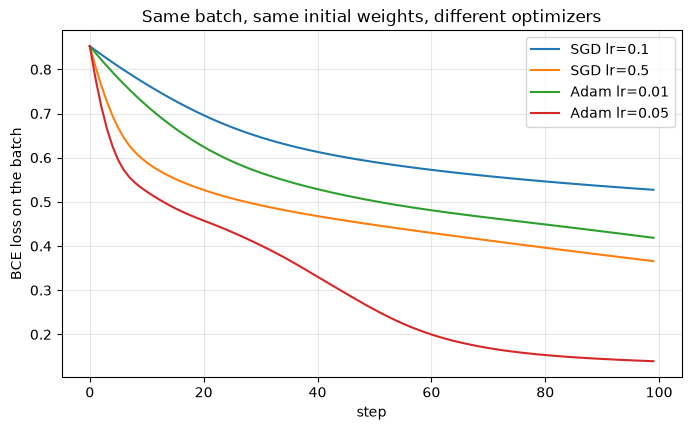

In [9]:
plt.figure(figsize=(8, 4.5))
for label, losses in results.items():
    plt.plot(losses, label=label)
plt.xlabel("step")
plt.ylabel("BCE loss on the batch")
plt.title("Same batch, same initial weights, different optimizers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Um passo de perto

O SGD anda proporcional ao gradiente; o primeiro passo do Adam é ~`lr` em todo peso.

In [10]:
for optimizer_class, kwargs in [(SGD, {"lr": 0.5}), (Adam, {"lr": 0.05})]:
    model = new_model()
    optimizer = optimizer_class(model.parameters(), **kwargs)
    before = [p.data.copy() for p in model.parameters()]

    optimizer.zero_grad()
    bce(model.forward(X_batch), y_batch).backward()
    optimizer.step()

    print(optimizer_class.__name__, kwargs)
    for name, p, old in zip(names, model.parameters(), before):
        update = p.data - old
        print("  %-3s max |grad| %.4f   max |update| %.4f" % (name, np.max(np.abs(p.grad)), np.max(np.abs(update))))

SGD {'lr': 0.5}
  W0  max |grad| 0.0972   max |update| 0.0486
  b0  max |grad| 0.1210   max |update| 0.0605
  W1  max |grad| 0.0843   max |update| 0.0421
  b1  max |grad| 0.1167   max |update| 0.0583
Adam {'lr': 0.05}
  W0  max |grad| 0.0972   max |update| 0.0500
  b0  max |grad| 0.1210   max |update| 0.0500
  W1  max |grad| 0.0843   max |update| 0.0500
  b1  max |grad| 0.1167   max |update| 0.0500


### Pesos antes e depois de um passo

No SGD, `novo = antigo - lr * grad` (camada de saída).

In [11]:
model = new_model()
optimizer = SGD(model.parameters(), lr=0.5)
W_before = model.layers[-1].W.data.copy()

optimizer.zero_grad()
bce(model.forward(X_batch), y_batch).backward()
optimizer.step()

print("W before:\n", W_before)
print("\ngradient:\n", model.layers[-1].W.grad)
print("\nW after:\n", model.layers[-1].W.data)
print("\ncheck  W_before - lr * grad == W_after:",
      np.allclose(W_before - 0.5 * model.layers[-1].W.grad, model.layers[-1].W.data))

W before:
 [[-0.817  -0.6508  0.2955]
 [ 0.2549  0.1999 -0.2015]
 [ 0.8612  0.8328  0.3214]
 [ 0.2606  0.3264 -0.1924]
 [-0.632   0.3836  0.0439]]

gradient:
 [[-0.0629 -0.0369  0.0305]
 [ 0.064   0.0283  0.0009]
 [ 0.0201  0.0843 -0.0281]
 [ 0.0595 -0.0081  0.0093]
 [-0.064  -0.0426  0.037 ]]

W after:
 [[-0.7855 -0.6323  0.2803]
 [ 0.2229  0.1857 -0.2019]
 [ 0.8511  0.7907  0.3354]
 [ 0.2309  0.3304 -0.197 ]
 [-0.6     0.4049  0.0254]]

check  W_before - lr * grad == W_after: True
